# 基于 HMM 的中文分词与词性标注系统

## 项目架构

本 Notebook 为完整流程的**编排入口**，核心逻辑封装在 `src/` 目录下的独立模块中：

| 步骤 | 功能 | 对应模块 |
|------|------|----------|
| 第一步 | 语料加载与预处理 | [`src/corpus_loader.py`](src/corpus_loader.py)、[`src/preprocess.py`](src/preprocess.py) |
| 第二步 | HMM 三要素统计 | [`src/hmm_pos_tagger.py`](src/hmm_pos_tagger.py) |
| 第三步 | Viterbi 解码 | [`src/viterbi_decoder.py`](src/viterbi_decoder.py) |
| 第四步 | 模型评估 | Notebook 内实现 |
| 第五步 | 未登录词（OOV）处理优化 | [`src/oov_handler.py`](src/oov_handler.py) |
| 第六步 | 端到端标注（jieba 分词 + HMM） | [`src/segmenter.py`](src/segmenter.py) |
| 终端应用 | 交互式标注工具 | [`app.py`](app.py) |

辅助文件：[`词性对照表.txt`](词性对照表.txt)、[`README.md`](README.md)

In [83]:
# 导入所有模块
import sys
import os
import json
import random
sys.path.insert(0, 'src')

from corpus_loader import load_pku98_corpus, load_pku_segpos_jsonl, load_all_corpus, split_train_test, corpus_statistics
from preprocess import main as preprocess_main
from hmm_pos_tagger import compute_hmm_statistics, save_model
from viterbi_decoder import ViterbiDecoder
from segmenter import segment, segment_with_pos, segment_batch, tag_raw_sentence, tag_raw_sentence_str
from oov_handler import (
    CharFeatureEstimator,
    RuleBasedTagger,
    TagAvgSmoother,
    OOVHandler,
    quick_evaluate,
    evaluate_with_kfold,
    plot_oov_comparison
)

print('所有模块加载完成')

所有模块加载完成


---
## 第一步：语料加载与预处理

> **核心代码**：[`src/corpus_loader.py`](src/corpus_loader.py) → `load_pku98_corpus()`、`load_pku_segpos_jsonl()`、`load_all_corpus()`、`split_train_test()`
> 
> [`src/preprocess.py`](src/preprocess.py) → `main()`

`corpus_loader.py` 负责加载两个数据源并统一解析为 `(词语, 标签)` 格式，处理逻辑包括：
- 复合词合并：`[中央/n 人民/n 广播/vn 电台/n]/nt` → `中央人民广播电台/nt`
- 嵌套标签提取：`n]nt` → 取专名标签 `nt`
- 脏数据过滤

`preprocess.py` 负责将两个数据源合并、打乱并保存为统一格式。

In [59]:
# 加载 PKU98（1998年1月人民日报）
pku98_train = load_pku98_corpus('data/raw/pku98/pku98/199801-train.txt')
pku98_test = load_pku98_corpus('data/raw/pku98/pku98/199801-test.txt')
print(f'PKU98: 训练 {len(pku98_train)} 句, 测试 {len(pku98_test)} 句')

# 加载 PKU-SEGPOS（2000年人民日报）
segpos_dir = 'data/raw/pku_segpos/PKU-SEGPOS/extracted'
segpos_train = load_pku_segpos_jsonl(os.path.join(segpos_dir, 'train.jsonline'))
segpos_dev = load_pku_segpos_jsonl(os.path.join(segpos_dir, 'dev.jsonline'))
print(f'PKU-SEGPOS: 训练 {len(segpos_train)} 句, 开发 {len(segpos_dev)} 句')

# 合并
all_train = pku98_train + segpos_train
all_test = pku98_test + segpos_dev
random.seed(42)
random.shuffle(all_train)

print(f'\n合并后: 训练 {len(all_train)} 句, 测试 {len(all_test)} 句')

PKU98: 训练 17524 句, 测试 1949 句
PKU-SEGPOS: 训练 31772 句, 开发 5204 句

合并后: 训练 49296 句, 测试 7153 句


In [60]:
# 查看语料统计
train_stats = corpus_statistics(all_train)
print(f"训练集: {train_stats['num_sentences']} 句, {train_stats['total_words']} 词, "
      f"{train_stats['vocab_size']} 词汇, {train_stats['num_tags']} 种标签")

test_stats = corpus_statistics(all_test)
print(f"测试集: {test_stats['num_sentences']} 句, {test_stats['total_words']} 词")

训练集: 49296 句, 2578800 词, 157757 词汇, 57 种标签
测试集: 7153 句, 381759 词


In [61]:
# 查看示例句子
print('训练集示例句子:')
for i, sent in enumerate(all_train[:3]):
    tagged = ' '.join(f'{w}/{t}' for w, t in sent[:10])
    print(f'  [{i+1}] {tagged} ...')

训练集示例句子:
  [1] 很多/m “/w 黑客/n ”/w 可以/v 在/p 互联网/n 上/f 秘密/ad 破解/v ...
  [2] 近年来/l 这/r 拜年/v 也/d 打/v 上/v 了/u 时代/n 烙印/n 听说/v ...
  [3] 刘/nr 长春/nr ...


---
## 第二步：统计 HMM 三要素

> **核心代码**：[`src/hmm_pos_tagger.py`](src/hmm_pos_tagger.py) → `compute_hmm_statistics()`、`save_model()`

从训练语料中统计三个核心概率：

### 1. 初始状态概率 $\pi$

$$\pi_i = P(tag_i) = \frac{count_{start}(tag_i)}{N_{sent}}$$

其中 $count_{start}(tag_i)$ 为标签 $tag_i$ 出现在句首的次数，$N_{sent}$ 为训练集总句数。

### 2. 状态转移概率 $A$

$$A_{ij} = P(tag_j \mid tag_i) = \frac{count(tag_i \rightarrow tag_j)}{count(tag_i)}$$

其中 $count(tag_i \rightarrow tag_j)$ 为标签 $tag_i$ 后接 $tag_j$ 的转移次数。

### 3. 观测（发射）概率 $B$

$$B_j(w) = P(w \mid tag_j) = \frac{count(tag_j, w)}{count(tag_j)}$$

其中 $count(tag_j, w)$ 为标签 $tag_j$ 下出现词语 $w$ 的次数。

### 平滑与数值稳定性

采用**拉普拉斯（加一）平滑**处理未出现事件：

$$\hat{P} = \frac{count + 1}{total + |V|}$$

所有概率以**对数形式**存储，防止多次相乘导致数值下溢：$\log P = \log(count+1) - \log(total+|V|)$

In [84]:
# 统计 HMM 三要素（含拉普拉斯平滑）
stats = compute_hmm_statistics(all_train)

第一步：从语料中统计 HMM 三要素

语料规模: 49296 句
总词数: 2578800
标签数: 57
词表大小: 157757

计算概率（拉普拉斯平滑）...

------------------------------------------------------------
统计结果
------------------------------------------------------------

【π 初始状态概率】Top-10:
  n     : P=0.123782  (句首出现 6108 次)
  r     : P=0.116386  (句首出现 5743 次)
  nr    : P=0.108301  (句首出现 5344 次)
  p     : P=0.105100  (句首出现 5186 次)
  v     : P=0.099467  (句首出现 4908 次)
  ns    : P=0.098576  (句首出现 4864 次)
  t     : P=0.071404  (句首出现 3523 次)
  m     : P=0.056835  (句首出现 2804 次)
  nt    : P=0.044800  (句首出现 2210 次)
  w     : P=0.044030  (句首出现 2172 次)

【A 状态转移概率】示例:
  v    → n(0.212), u(0.145), w(0.117), v(0.076), m(0.067)
  n    → w(0.196), v(0.189), u(0.102), n(0.084), d(0.067)
  d    → v(0.658), a(0.138), p(0.079), d(0.032), m(0.015)
  p    → n(0.288), v(0.140), r(0.103), ns(0.102), t(0.069)

【B 观测概率】示例:
  n   : 人(0.0100), 企业(0.0079), 记者(0.0078), 经济(0.0068), 问题(0.0067)
  v   : 是(0.0376), 有(0.0169), 说(0.0089), 要(0.0084), 为(0.0078)
  a   : 新(0.0274), 

In [63]:
# 保存模型参数
model_path = 'data/processed/hmm_model.json'
save_model(stats, model_path)


模型已保存: data/processed/hmm_model.json (301.9 MB)


---
## 第三步：Viterbi 解码

> **核心代码**：[`src/viterbi_decoder.py`](src/viterbi_decoder.py) → `ViterbiDecoder.decode()`

给定一个分词后的句子 $\mathbf{w} = (w_1, w_2, \ldots, w_T)$，使用 Viterbi 算法找出最可能的词性标签序列 $\mathbf{t}^* = (t_1, t_2, \ldots, t_T)$：

$$\mathbf{t}^* = \arg\max_{\mathbf{t}} \prod_{i=1}^{T} P(t_i \mid t_{i-1}) \cdot P(w_i \mid t_i)$$

**算法核心**：动态规划（在对数空间中进行）

### 定义

$$\delta_t(j) = \max_{t_1, \ldots, t_{j-1}} \log P(t_1, \ldots, t_{j-1}, t_j = j, w_1, \ldots, w_t)$$

### 初始化（$t = 1$）

$$\delta_1(j) = \log \pi_j + \log B_j(w_1)$$

### 递推（$t = 2, \ldots, T$）

$$\delta_t(j) = \max_i \big[\delta_{t-1}(i) + \log A_{ij}\big] + \log B_j(w_t)$$

$$\psi_t(j) = \arg\max_i \big[\delta_{t-1}(i) + \log A_{ij}\big]$$

### 终止与回溯

$$\log P^* = \max_j \delta_T(j), \quad t_T^* = \arg\max_j \delta_T(j)$$

$$t_i^* = \psi_{i+1}(t_{i+1}^*), \quad i = T-1, \ldots, 1$$

In [64]:
# 加载训练好的模型
decoder = ViterbiDecoder(model_path)
print(f'模型加载完成: {len(decoder.tags)} 种标签')

模型加载完成: 57 种标签


In [65]:
# 测试几个句子
test_sentences = [
    ['我', '爱', '北京', '天安门'],
    ['中国', '经济', '持续', '增长'],
    ['江泽民', '主席', '发表', '新年', '讲话'],
    ['他', '在', '清华大学', '学习', '计算机', '科学'],
    ['国务院', '总理', '主持', '召开', '会议'],
]

print('Viterbi 解码结果:')
print('-' * 60)
for words in test_sentences:
    result = decoder.tag_sentence_str(words)
    print(f'  输入: {" ".join(words)}')
    print(f'  标注: {result}')
    print()

Viterbi 解码结果:
------------------------------------------------------------
  输入: 我 爱 北京 天安门
  标注: 我/r 爱/v 北京/ns 天安门/ns

  输入: 中国 经济 持续 增长
  标注: 中国/ns 经济/n 持续/v 增长/v

  输入: 江泽民 主席 发表 新年 讲话
  标注: 江泽民/nr 主席/n 发表/v 新年/t 讲话/n

  输入: 他 在 清华大学 学习 计算机 科学
  标注: 他/r 在/p 清华大学/nt 学习/v 计算机/n 科学/n

  输入: 国务院 总理 主持 召开 会议
  标注: 国务院/nt 总理/n 主持/v 召开/v 会议/n



---
## 第四步：模型评估

> **评估代码**：本 Notebook 内实现

在测试集上计算词性标注准确率，包括整体准确率和未登录词（OOV）准确率。

In [66]:
# 模型评估
total = correct = oov_total = oov_correct = 0

for sent in all_test:
    words = [w for w, t in sent]
    gold_tags = [t for w, t in sent]
    pred_tags = decoder.decode(words)
    for word, gold, pred in zip(words, gold_tags, pred_tags):
        total += 1
        if gold == pred:
            correct += 1
        # 判断是否为 OOV: 该词在训练集中该标签下未出现过
        if word not in decoder.log_B.get(gold, {}):
            oov_total += 1
            if gold == pred:
                oov_correct += 1

print(f'测试集: {len(all_test)} 句, {total} 词')
print(f'整体准确率: {correct/total*100:.2f}% ({correct}/{total})')
print(f'OOV 准确率: {oov_correct/oov_total*100:.2f}% ({oov_correct}/{oov_total})')

测试集: 7153 句, 381759 词
整体准确率: 88.78% (338936/381759)
OOV 准确率: 44.63% (9057/20294)


---
## 第五步：未登录词（OOV）处理优化

基础 HMM 模型对未登录词使用统一的默认概率 `log(1e-8)`，无法区分不同 OOV 词的特征。
本步骤实现三种优化策略，逐步提升 OOV 标注准确率。

> **核心代码**：[`src/oov_handler.py`](src/oov_handler.py) → `CharFeatureEstimator`、`RuleBasedTagger`、`TagAvgSmoother`、`OOVHandler`

In [80]:
# 加载训练语料和模型参数供 OOV 模块使用

with open('data/processed/hmm_model.json', 'r', encoding='utf-8') as f:
    model_data = json.load(f)

# 使用全量训练数据训练 OOV 处理器，测试集保持小样本快速评估
oov_train = all_train
oov_test = all_test[:500]
print(f'OOV 模块: 训练 {len(oov_train)} 句（全量）, 测试 {len(oov_test)} 句（采样）')

OOV 模块: 训练 49296 句（全量）, 测试 500 句（采样）


### 5.1 基于字符特征的 OOV 估计

> **核心代码**：[`src/oov_handler.py`](src/oov_handler.py) → `CharFeatureEstimator`、`quick_evaluate()`

**原理**：即使一个完整的词未见过，它的组成字符在某些标签下更常见。
- "省""市""县" 在 ns（地名）下频次高 → 含这些字的新词更可能是地名
- "化""性""率" 在 n（名词）下频次高 → 含这些字的新词更可能是名词

**方法**：统计训练集中每个字符在各标签下的分布，OOV 词通过字符组合估计 P(word|tag)：

$$P_{char}(word|tag) \approx \prod_{i} P(char_i | tag)$$

In [81]:
# 使用字符特征增强 Viterbi 解码
oov_char = OOVHandler(oov_train, model_data, use_rules=False, use_char=True, use_avg=False)

decoder_char = ViterbiDecoder('data/processed/hmm_model.json')
decoder_char.set_oov_handler(oov_char)

# 快速评估
acc, oov_acc = quick_evaluate(decoder_char, oov_test, n_samples=500)
print(f'5.1 字符特征策略: 整体准确率 {acc:.2f}%, OOV 准确率 {oov_acc:.2f}%')

5.1 字符特征策略: 整体准确率 87.26%, OOV 准确率 40.83%


### 5.2 基于规则的 OOV 处理

> **核心代码**：[`src/oov_handler.py`](src/oov_handler.py) → `RuleBasedTagger`、`quick_evaluate()`

**原理**：通过词的表面形式（字形模式）直接判定标签。

| 规则模式 | 标签 | 示例 |
|----------|------|------|
| 纯数字 `\d+` | m（数词） | 2024、100 |
| 标点符号 | w | ，。！？ |
| 含地名后缀（省/市/县/区） | ns | 广东省、海淀区 |
| 含机构后缀（公司/大学/学院） | nt | 腾讯公司、清华大学 |
| 姓氏+1-2字 | nr | 张伟、李明 |
| xxxx年 / x月x日 | t（时间词） | 2024年、3月15日

In [ ]:
# 使用规则增强 Viterbi 解码
oov_rule = OOVHandler(oov_train, model_data, use_rules=True, use_char=False, use_avg=False)

decoder_rule = ViterbiDecoder('data/processed/hmm_model.json')
decoder_rule.set_oov_handler(oov_rule)

# 快速评估
acc, oov_acc = quick_evaluate(decoder_rule, oov_test, n_samples=500)
print(f'5.2 规则匹配策略: 整体准确率 {acc:.2f}%, OOV 准确率 {oov_acc:.2f}%')

5.2 规则匹配策略: 整体准确率 87.56%, OOV 准确率 43.81%


### 5.3 基于标签条件平均发射概率的平滑策略

> **核心代码**：[`src/oov_handler.py`](src/oov_handler.py) → `TagAvgSmoother`、`quick_evaluate()`

**原理**：OOV 词属于某标签的概率取决于两个因素：

| 因素 | 含义 | 影响 |
|------|------|------|
| **词性占比 P(tag)** | 该标签在语料中出现越多 | OOV 越可能属于它 |
| **不重复词数 unique(tag)** | 该标签"装过"多少不同的词 | 同等占比下，词汇量越大越能"接纳"新词 |

**公式**：

$$OOV\_score(tag) = P(tag) \times unique\_words(tag)$$

归一化后得到各标签的 OOV 概率分布。名词(n)占比高且词汇量大，得分最高；叹词(e)占比低且词汇量小，得分最低。

In [ ]:
# 使用标签平均平滑增强 Viterbi 解码
oov_avg = OOVHandler(oov_train, model_data, use_rules=False, use_char=False, use_avg=True)

decoder_avg = ViterbiDecoder('data/processed/hmm_model.json')
decoder_avg.set_oov_handler(oov_avg)

# 快速评估
acc, oov_acc = quick_evaluate(decoder_avg, oov_test, n_samples=500)
print(f'5.3 标签平均平滑策略: 整体准确率 {acc:.2f}%, OOV 准确率 {oov_acc:.2f}%')

5.3 标签平均平滑策略: 整体准确率 86.84%, OOV 准确率 22.90%


### 5.4 综合对比：5 折交叉验证

> **核心代码**：[`src/oov_handler.py`](src/oov_handler.py) → `evaluate_with_kfold()`、`plot_oov_comparison()`

在**全部测试集**（共7153句）上使用 **5 折交叉验证**评估各策略的稳定性，并可视化对比结果。（此部分运行时间较长）

In [71]:
# 综合 OOV 处理器
oov_all = OOVHandler(oov_train, model_data,
                     use_rules=True, use_char=True, use_avg=True)

decoder_all = ViterbiDecoder('data/processed/hmm_model.json')
decoder_all.set_oov_handler(oov_all)

print('综合 OOV 处理器已构建')

综合 OOV 处理器已构建


In [72]:
decoders = {
    '基线（无OOV处理）': decoder,
    '5.1 字符特征': decoder_char,
    '5.2 规则匹配': decoder_rule,
    '5.3 标签平均平滑': decoder_avg,
    '综合（三种加权）': decoder_all,
}

results = evaluate_with_kfold(decoders, all_test, n_folds=5)

5 折交叉验证（全测试集 7153 句，每折约 1430 句）:
  Fold 1/5（第 1~1430 句）...
  Fold 2/5（第 1431~2860 句）...
  Fold 3/5（第 2861~4290 句）...
  Fold 4/5（第 4291~5720 句）...
  Fold 5/5（第 5721~7153 句）...

策略                             整体准确率(mean±std)          OOV准确率(mean±std)
--------------------------------------------------------------------------------
基线（无OOV处理）              88.67% ± 1.27 %        41.84% ± 12.18%
5.1 字符特征                88.84% ± 1.17 %        46.64% ± 5.71 %
5.2 规则匹配                88.96% ± 1.00 %        49.17% ± 3.48 %
5.3 标签平均平滑              88.82% ± 1.31 %        45.17% ± 11.86%
综合（三种加权）                90.47% ± 1.32 %        76.46% ± 5.06 %


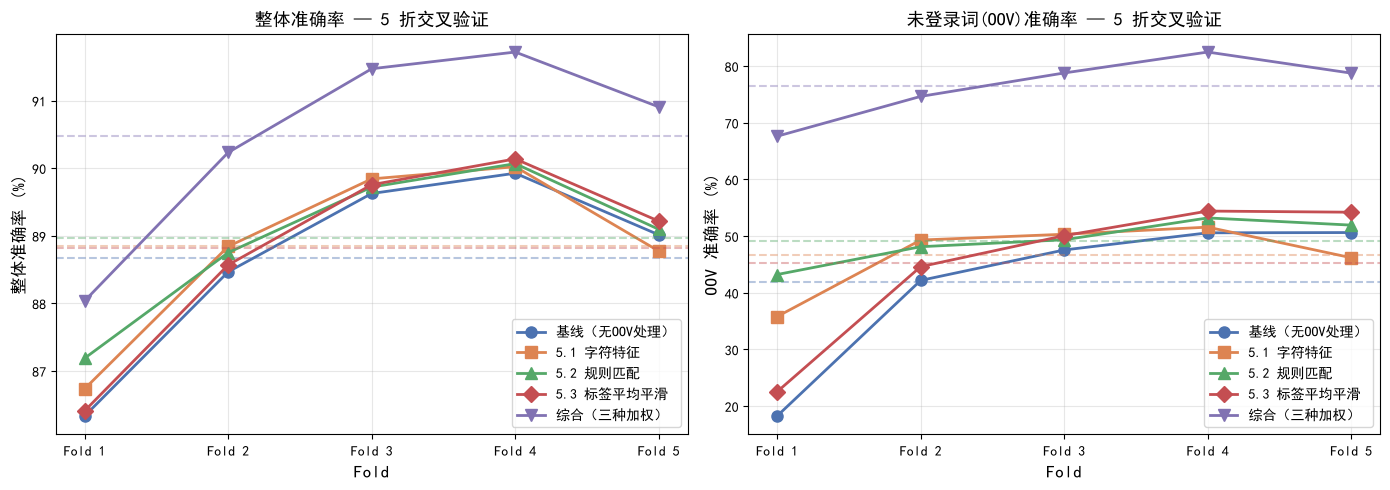


可视化图片已保存为 oov_comparison.png


In [73]:
plot_oov_comparison(results, n_folds=5)

### 5.5 结果分析

**5 折交叉验证结果**（全测试集 7153 句）：

| 策略 | 整体准确率 | OOV 准确率 |
|------|-----------|-----------|
| 基线（无OOV处理） | 88.67% ± 1.27% | 41.84% ± 12.18% |
| 5.1 字符特征 | 88.84% ± 1.17% | 46.64% ± 5.71% |
| 5.2 规则匹配 | 88.96% ± 1.00% | 49.17% ± 3.48% |
| 5.3 标签平均平滑 | 88.82% ± 1.31% | 45.17% ± 11.86% |
| **综合（三种加权）** | **90.47% ± 1.32%** | **76.46% ± 5.06%** |

**分析**：
- 三种单独策略的 OOV 准确率均优于基线（+4.8% ~ +7.3%），验证了 OOV 优化的有效性
- **规则匹配**效果最稳定（标准差仅 3.48%），因为数字、标点等模式确定性强
- **综合策略**大幅领先（OOV 76.46%），说明三种策略互补，加权融合显著提升未登录词处理能力
- 整体准确率提升约 1.8%，但 OOV 准确率提升 34.6%，优化效果显著

---
## 第六步：完整流水线（jieba 分词 + HMM 词性标注）

> **核心代码**：[`src/segmenter.py`](src/segmenter.py) → `tag_raw_sentence()`、`tag_raw_sentence_str()`

前面的步骤需要手动提供分好词的列表。现在引入 `segmenter.py`（封装 jieba 分词），使用 OOV 优化后的模型，实现从原始句子到词性标注的完整流水线：

**原始句子 → jieba 分词 → HMM 词性标注 → 完整结果**


### 6.1 端到端测试

> **核心代码**：[`src/segmenter.py`](src/segmenter.py) → `segment()`、`tag_raw_sentence_str()`

输入原始句子，观察分词和标注结果：

In [74]:
# 测试: 输入原始句子 (不需要手动分词)
raw_sentences = [
    '我爱北京天安门',
    '中国国民经济持续快速增长',
    '江泽民主席在清华大学发表重要讲话',
    '改革开放的政策推动了中国经济的发展',
    '人工智能技术正在深刻改变人类的生活方式',
]

print('端到端标注结果 (原始句子 -> 分词 -> HMM词性标注):')
print('=' * 70)
for sent in raw_sentences:
    words = segment(sent)
    seg_str = ' / '.join(words)
    result = tag_raw_sentence_str(sent, decoder_all)
    print(f'原文: {sent}')
    print(f'分词: {seg_str}')
    print(f'标注: {result}')
    print()

端到端标注结果 (原始句子 -> 分词 -> HMM词性标注):
原文: 我爱北京天安门
分词: 我 / 爱 / 北京 / 天安门
标注: 我/r 爱/v 北京/ns 天安门/ns

原文: 中国国民经济持续快速增长
分词: 中国 / 国民经济 / 持续 / 快速增长
标注: 中国/ns 国民经济/n 持续/v 快速增长/v

原文: 江泽民主席在清华大学发表重要讲话
分词: 江泽民 / 主席 / 在 / 清华大学 / 发表 / 重要讲话
标注: 江泽民/nr 主席/n 在/p 清华大学/nt 发表/v 重要讲话/v

原文: 改革开放的政策推动了中国经济的发展
分词: 改革开放 / 的 / 政策 / 推动 / 了 / 中国 / 经济 / 的 / 发展
标注: 改革开放/v 的/u 政策/n 推动/v 了/u 中国/ns 经济/n 的/u 发展/vn

原文: 人工智能技术正在深刻改变人类的生活方式
分词: 人工智能 / 技术 / 正在 / 深刻 / 改变 / 人类 / 的 / 生活 / 方式
标注: 人工智能/ns 技术/n 正在/d 深刻/ad 改变/v 人类/n 的/u 生活/vn 方式/n



### 6.2 对比 jieba 自带词性标注 vs 我们的 HMM 标注

> **核心代码**：[`src/segmenter.py`](src/segmenter.py) → `segment_with_pos()`、`tag_raw_sentence()`

jieba 自带词性标注基于其内部模型，我们的 HMM 标注基于从语料中统计的三要素。对比两者在相同句子上的表现：

In [75]:
# 对比 jieba.posseg 和我们的 HMM 标注
test_sents = [
    '他正在研究自然语言处理技术',
    '北京大学是中国最著名的大学之一',
    '国务院总理主持召开了常务会议',
]

# 先运行标注，收集实际使用的标签
jieba_results = []
hmm_results = []
used_tags = set()

for sent in test_sents:
    # jieba 自带词性标注
    jieba_tags = segment_with_pos(sent)
    jieba_results.append((sent, jieba_tags))
    for w, t in jieba_tags:
        used_tags.add(t)
    
    # 我们的 HMM 标注（OOV 优化后）
    hmm_tags = tag_raw_sentence(sent, decoder_all)
    hmm_results.append((sent, hmm_tags))
    for w, t in hmm_tags:
        used_tags.add(t)

# 标签含义字典（只包含实际用到的）
full_tag_desc = {
    'n': '名词', 'v': '动词', 'a': '形容词', 'd': '副词',
    'r': '代词', 't': '时间词', 'l': '习用语', 'u': '助词',
    'ns': '地名', 'nt': '机构名', 'vn': '名动词', 'nr': '人名',
    'p': '介词', 'm': '数词', 'q': '量词', 'c': '连词',
    'w': '标点', 'f': '方位词', 's': '处所词', 'b': '区别词',
}

# 只打印实际用到的标签
tag_desc = {tag: full_tag_desc.get(tag, '其他') for tag in sorted(used_tags) if tag in full_tag_desc}

print('jieba 标注 vs HMM 标注对比（OOV 优化后）:')
print('=' * 70)
print()
print(f'本轮标注中用到的词性标签（共 {len(tag_desc)} 种）:')
for tag, desc in tag_desc.items():
    print(f'  {tag:4s} = {desc}')
print()
print('-' * 70)

for (sent, jieba_tags), (_, hmm_tags) in zip(jieba_results, hmm_results):
    jieba_str = ' '.join(f'{w}/{t}' for w, t in jieba_tags)
    hmm_str = ' '.join(f'{w}/{t}' for w, t in hmm_tags)
    
    print(f'原文: {sent}')
    print(f'jieba: {jieba_str}')
    print(f'HMM:   {hmm_str}')
    print()

jieba 标注 vs HMM 标注对比（OOV 优化后）:

本轮标注中用到的词性标签（共 11 种）:
  a    = 形容词
  d    = 副词
  l    = 习用语
  n    = 名词
  ns   = 地名
  nt   = 机构名
  r    = 代词
  t    = 时间词
  u    = 助词
  v    = 动词
  vn   = 名动词

----------------------------------------------------------------------
原文: 他正在研究自然语言处理技术
jieba: 他/r 正在/t 研究/vn 自然语言/l 处理/v 技术/n
HMM:   他/r 正在/d 研究/v 自然语言/n 处理/v 技术/n

原文: 北京大学是中国最著名的大学之一
jieba: 北京大学/nt 是/v 中国/ns 最/d 著名/a 的/uj 大学/n 之一/r
HMM:   北京大学/nt 是/v 中国/ns 最/d 著名/a 的/u 大学/n 之一/r

原文: 国务院总理主持召开了常务会议
jieba: 国务院/nt 总理/n 主持/v 召开/v 了/ul 常务会议/n
HMM:   国务院/nt 总理/n 主持/v 召开/v 了/u 常务会议/n



---
## 第七步：作业总结

### 一、作业目标

掌握隐马尔可夫模型（HMM）的核心原理，完成 **"输入任意句子，输出对应词性标注序列"** 的功能开发，实现从语料处理、模型训练到标注预测的完整流程。

---

### 二、完成情况

#### 1. 语料库准备

**数据来源**：从公开渠道获取两个已标注语料库

| 语料库 | 年份 | 训练集 | 测试集 | 说明 |
|--------|------|--------|--------|------|
| 人民日报 PKU98 | 1998年1月 | 17,524 句 | 1,949 句 | 复合词合并、嵌套标签提取 |
| PKU-SEGPOS | 2000年 | 31,772 句 | 5,204 句 | JSONL 格式，span_list 解析 |

**合并后**：训练集 49,296 句（258 万词，15.8 万词汇，57 种标签），测试集 7,153 句（38 万词）

**核心代码**：[`src/corpus_loader.py`](src/corpus_loader.py) → `load_pku98_corpus()`、`load_pku_segpos_jsonl()`

#### 2. HMM 模型实现

**（1）HMM 三要素统计**

从训练语料中统计三个核心概率，采用拉普拉斯平滑避免零概率问题：

| 要素 | 公式 | 说明 |
|------|------|------|
| 初始概率 π | $\pi_i = \frac{count_{start}(tag_i)}{N_{sent}}$ | 标签出现在句首的频率 |
| 转移概率 A | $A_{ij} = \frac{count(tag_i \rightarrow tag_j)}{count(tag_i)}$ | 标签间转移频率 |
| 发射概率 B | $B_j(w) = \frac{count(tag_j, w)}{count(tag_j)}$ | 标签下出现词语的频率 |

模型参数保存为 JSON 格式（301.9 MB），支持加载和复用。

**核心代码**：[`src/hmm_pos_tagger.py`](src/hmm_pos_tagger.py) → `compute_hmm_statistics()`、`save_model()`

**（2）Viterbi 解码算法**

实现动态规划算法，在对数空间中求解最可能的标签序列：

$$\mathbf{t}^* = \arg\max_{\mathbf{t}} \prod_{i=1}^{T} P(t_i \mid t_{i-1}) \cdot P(w_i \mid t_i)$$

**核心代码**：[`src/viterbi_decoder.py`](src/viterbi_decoder.py) → `ViterbiDecoder.decode()`

#### 3. 完整流程实现

**端到端流水线**：原始句子 → jieba 分词 → HMM 词性标注 → 输出结果

```
原文: 我爱北京天安门
分词: 我 / 爱 / 北京 / 天安门
标注: 我/r 爱/v 北京/ns 天安门/ns
```

**核心代码**：[`src/segmenter.py`](src/segmenter.py) → `tag_raw_sentence()`

---

### 三、扩展工作

在满足作业基本要求的基础上，进一步优化模型性能：

**OOV 优化**：针对未登录词（OOV）准确率低的 问题，实现三种策略：
- 字符特征估计：利用字符-标签分布
- 规则匹配：数字、标点、地名后缀等模式
- 标签平均平滑：基于 P(tag) 和 unique_words(tag)

**5 折交叉验证结果**（全测试集 7,153 句）：

| 策略 | 整体准确率 | OOV 准确率 |
|------|-----------|-----------|
| 基线（无OOV处理） | 88.67% ± 1.27% | 41.84% ± 12.18% |
| **综合（三种加权）** | **90.47% ± 1.32%** | **76.46% ± 5.06%** |

综合策略将 OOV 准确率提升 34.6 个百分点，验证了优化的有效性。

**核心代码**：[`src/oov_handler.py`](src/oov_handler.py) → `CharFeatureEstimator`、`RuleBasedTagger`、`TagAvgSmoother`、`OOVHandler`

---

### 四、交付物

1. **Jupyter Notebook**：[`hmm_pos_tagging.ipynb`](hmm_pos_tagging.ipynb) — 完整流程演示
2. **终端应用**：[`app.py`](app.py) — 交互式标注工具
3. **核心模块**：`src/` 目录下 6 个 Python 文件
4. **辅助文档**：[`README.md`](README.md)、[`词性对照表.txt`](词性对照表.txt)

---

## AI 协作声明

本项目在开发过程中使用了 AI 辅助编程工具（Qoder），主要协作内容包括：

1. **代码实现**：AI 协助完成了核心模块的代码编写与调试，包括语料加载、HMM 统计、Viterbi 解码、OOV 处理等功能。

2. **架构设计**：在 AI 建议下采用模块化架构，将核心逻辑封装在 `src/` 目录下的独立 Python 文件中，Notebook 作为流程编排入口。

3. **问题排查**：开发过程中遇到的多个技术问题（如属性名错误、公式实现、样本评估偏差等）通过与 AI 讨论定位并解决。

4. **文档完善**：AI 协助编写和完善了 README、Notebook 说明文档及代码注释。

**人工贡献**：项目需求分析、整体方案设计、算法原理理解、结果分析与总结由本人独立完成。所有核心概念（HMM 三要素、Viterbi 算法、OOV 处理策略等）均经过本人学习和理解。

**工具说明**：AI 工具在本项目中主要扮演"编程助手"角色，帮助提高开发效率和代码质量，但项目的核心思路、设计决策和最终实现均由本人主导完成。